# Assignment 2

## Students: <br>

Anton Maksymchuk Netterström <br>
Mauritz Almgren

In [123]:
%pip install ucimlrepo pandas numpy scikit-learn matplotlib scipy

Note: you may need to restart the kernel to use updated packages.


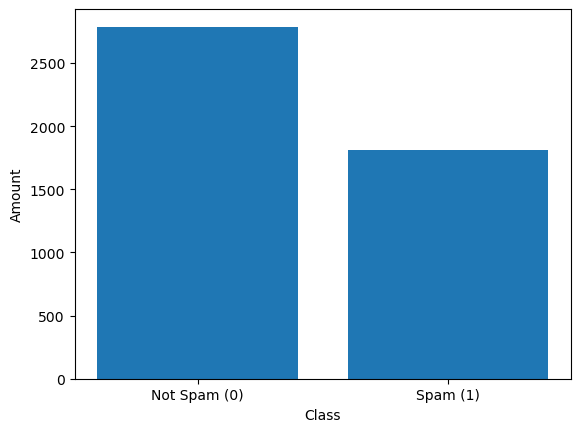

In [124]:
from ucimlrepo import fetch_ucirepo
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
from sklearn.model_selection import StratifiedKFold
from sklearn.model_selection import cross_validate
from sklearn.metrics import classification_report
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from scipy.stats import rankdata

# Used to fetch the dataset
spambase = fetch_ucirepo(id=94)
# All features in the dataset
X = spambase.data.features
# y is the Class with spam (1) and not spam (0)
y = spambase.data.targets

counts = y["Class"].value_counts()

plt.bar(counts.index, counts.values)
plt.xticks(counts.index, ["Not Spam (0)", "Spam (1)"])
plt.xlabel("Class")
plt.ylabel("Amount")
plt.show()

Ranking of fit time for each model.

In [133]:
X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=42, stratify=y)

skf = StratifiedKFold(n_splits=10, random_state=42, shuffle=True)

RF = RandomForestClassifier()
KNN = KNeighborsClassifier(n_neighbors=5) # Use default value for k-number neighbors
BN = GaussianNB()

y_train = np.ravel(y_train)

scores_RF = pd.DataFrame(cross_validate(RF, X_train, y_train, cv=skf, scoring=["accuracy", "f1"]))
scores_KNN = pd.DataFrame(cross_validate(KNN, X_train, y_train, cv=skf, scoring=["accuracy", "f1"]))
scores_NB = pd.DataFrame(cross_validate(BN, X_train, y_train, cv=skf, scoring=["accuracy", "f1"]))

fit_time_df = pd.DataFrame()

fit_time_df["Random Forest"] = scores_RF["fit_time"].round(6)

fit_time_df["KNN"] = scores_KNN["fit_time"].round(6)

fit_time_df["Naive Bayes"] = scores_NB["fit_time"].round(6)

fit_time_df_tot = fit_time_df.copy()

fit_time_df_tot.loc["avg"] = [np.mean(scores_RF["fit_time"]), np.mean(scores_KNN["fit_time"]), np.mean(scores_NB["fit_time"])]

fit_time_df_tot.loc["stdev"] = [np.std(scores_RF["fit_time"]), np.std(scores_KNN["fit_time"]), np.std(scores_NB["fit_time"])]

display(fit_time_df_tot)

fit_time_ranks = pd.DataFrame(rankdata(fit_time_df, method="min", axis=1))

time_ranked_df = pd.DataFrame()

time_ranked_df["Random Forest"] = (
    fit_time_df["Random Forest"].astype(str)
    + " "
    + "("
    + fit_time_ranks[0].astype(str)
    + ")"
)

time_ranked_df["KNN"] = (
    fit_time_df["KNN"].astype(str)
    + " "
    + "("
    + fit_time_ranks[1].astype(str)
    + ")"
)

time_ranked_df["Naive Bayes"] = (
    fit_time_df["Naive Bayes"].astype(str)
    + " "
    + "("
    + fit_time_ranks[2].astype(str)
    + ")"
)
time_ranked_df.loc["avg rank"] = [np.mean(fit_time_ranks[0]), np.mean(fit_time_ranks[1]), np.mean(fit_time_ranks[2])]

display(time_ranked_df)

mean_rank = np.mean(time_ranked_df.loc["avg rank"])

print(mean_rank)

,Random Forest,KNN,Naive Bayes
0,0.458556,0.003084,0.005034
1,0.467637,0.004349,0.005464
2,0.466440,0.004385,0.005193
3,0.484816,0.003890,0.005245
4,0.485749,0.004799,0.005406
5,0.505787,0.004475,0.005218
6,0.514603,0.004104,0.006255
7,0.539518,0.003763,0.005121
8,0.539595,0.004116,0.006139
9,0.549783,0.003592,0.005664


,Random Forest,KNN,Naive Bayes
0,0.458556 (3),0.003084 (1),0.005034 (2)
1,0.467637 (3),0.004349 (1),0.005464 (2)
2,0.46644 (3),0.004385 (1),0.005193 (2)
3,0.484816 (3),0.00389 (1),0.005245 (2)
4,0.485749 (3),0.004799 (1),0.005406 (2)
5,0.505787 (3),0.004475 (1),0.005218 (2)
6,0.514603 (3),0.004104 (1),0.006255 (2)
7,0.539518 (3),0.003763 (1),0.005121 (2)
8,0.539595 (3),0.004116 (1),0.006139 (2)
9,0.549783 (3),0.003592 (1),0.005664 (2)


2.0


Friedman table gives $\chi^2_F$ = 6.2 for n = 10 which are the folds and k = 3 which are the amount of models.

In [136]:
chi_sqrtF = 6.2

friedman = 3*np.sum((time_ranked_df.loc["avg rank"] - mean_rank)**2)

if friedman > chi_sqrtF:
    print("Proceed to Nemanyi test.")
else:
    print("Cannot draw conclusions about models performance, therefore reject H0 hypothesis")

Cannot draw conclusions about models performance, therefore reject H0 hypothesis
